<a href="https://colab.research.google.com/github/raymond-x-design/raymond-x-DataScience-GenAI-Submissions/blob/main/Assignment_1/2_05_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
We have seen some early examples of EDA in the previous notebooks. This session will expand on this with more examples - specifically a dataset on student performance. You can find the data on my.wbs as "students.csv" (in week 3, asynchronous tasks). As such, we start by importing the data:

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic.csv


In [3]:
sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("titanic.csv")

In [5]:
print("=== NUMERICAL SUMMARY ===")
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
num_summary = df[num_cols].describe().T
num_summary['skewness'] = df[num_cols].skew()
# Rename the '50%' column to 'median'
num_summary = num_summary.rename(columns={'50%': 'median'})
print(num_summary[['count', 'mean', 'std', 'min', 'median', 'max', 'skewness']].round(2))

=== NUMERICAL SUMMARY ===
       count   mean    std   min  median     max  skewness
Age    714.0  29.70  14.53  0.42   28.00   80.00      0.39
Fare   891.0  32.20  49.69  0.00   14.45  512.33      4.79
SibSp  891.0   0.52   1.10  0.00    0.00    8.00      3.70
Parch  891.0   0.38   0.81  0.00    0.00    6.00      2.75


In [6]:
print("\n=== CATEGORICAL DISTRIBUTIONS ===")
cat_cols = ['Survived', 'Pclass', 'Sex', 'Embarked']
for col in cat_cols:
    counts = df[col].value_counts(dropna=False)
    percents = df[col].value_counts(normalize=True, dropna=False) * 100
    cat_df = pd.DataFrame({'Count': counts, 'Percentage (%)': percents.round(2)})
    print(f"\nFeature: {col}")
    print(cat_df)


=== CATEGORICAL DISTRIBUTIONS ===

Feature: Survived
          Count  Percentage (%)
Survived                       
0           549           61.62
1           342           38.38

Feature: Pclass
        Count  Percentage (%)
Pclass                       
3         491           55.11
1         216           24.24
2         184           20.65

Feature: Sex
        Count  Percentage (%)
Sex                          
male      577           64.76
female    314           35.24

Feature: Embarked
          Count  Percentage (%)
Embarked                       
S           644           72.28
C           168           18.86
Q            77            8.64
NaN           2            0.22


/tmp/ipykernel_4266/2806501214.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_4266/2806501214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pclass', data=df, ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_4266/2806501214.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=df, ax=axes[0, 2], palette='Set2')
/tmp/ipykernel_4266/2806501214.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.

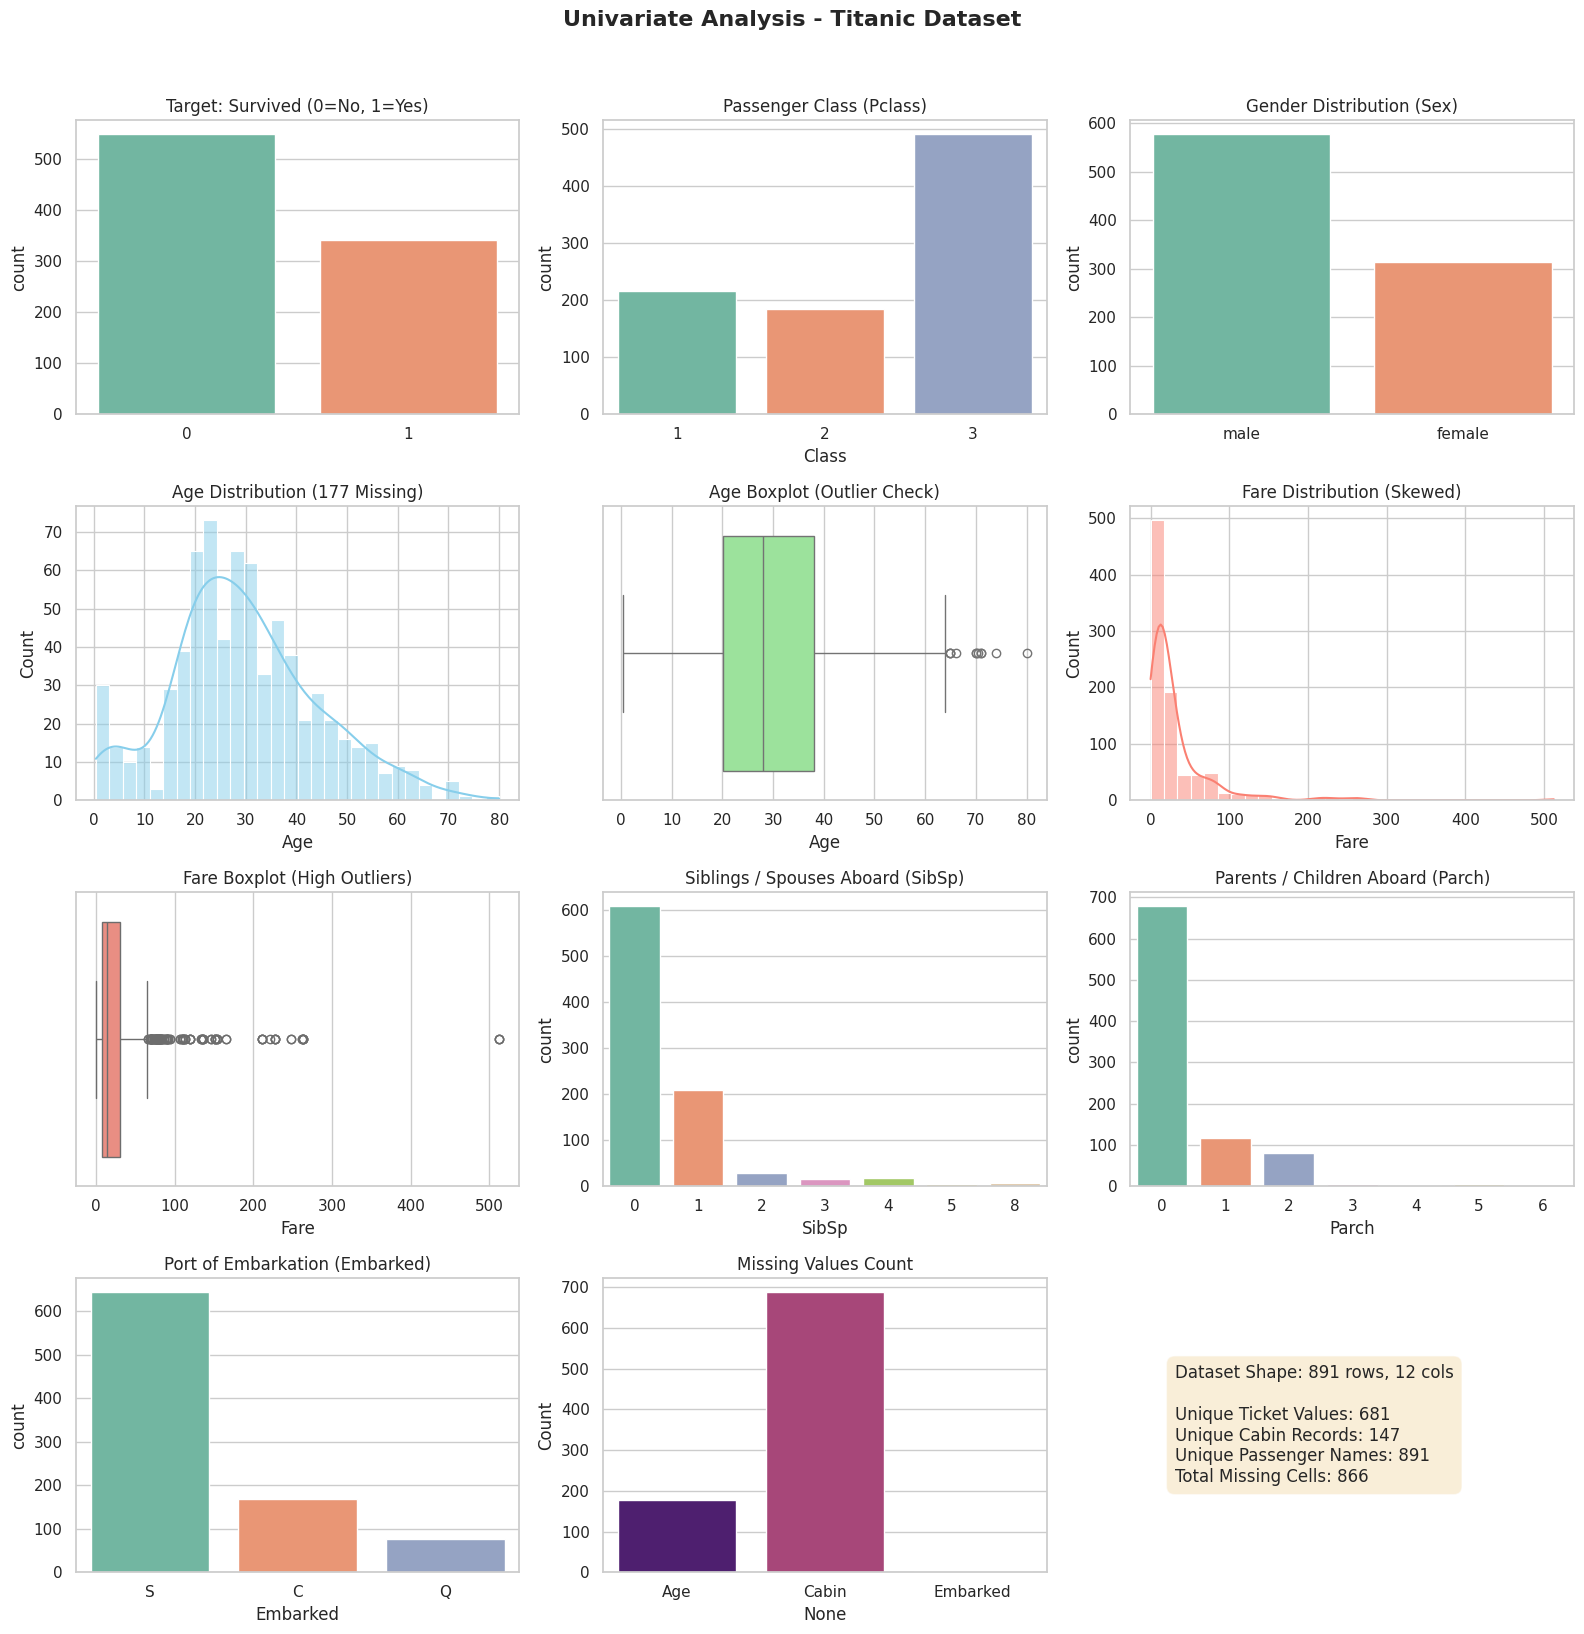

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
fig.suptitle('Univariate Analysis - Titanic Dataset', fontsize=16, fontweight='bold', y=1.02)
sns.countplot(x='Survived', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Target: Survived (0=No, 1=Yes)')
axes[0, 0].set_xlabel('')
sns.countplot(x='Pclass', data=df, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Passenger Class (Pclass)')
axes[0, 1].set_xlabel('Class')
sns.countplot(x='Sex', data=df, ax=axes[0, 2], palette='Set2')
axes[0, 2].set_title('Gender Distribution (Sex)')
axes[0, 2].set_xlabel('')
sns.histplot(df['Age'].dropna(), kde=True, ax=axes[1, 0], color='skyblue', bins=30)
axes[1, 0].set_title('Age Distribution (177 Missing)')
sns.boxplot(x=df['Age'], ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title('Age Boxplot (Outlier Check)')
sns.histplot(df['Fare'], kde=True, ax=axes[1, 2], color='salmon', bins=30)
axes[1, 2].set_title('Fare Distribution (Skewed)')
sns.boxplot(x=df['Fare'], ax=axes[2, 0], color='salmon')
axes[2, 0].set_title('Fare Boxplot (High Outliers)')
sns.countplot(x='SibSp', data=df, ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Siblings / Spouses Aboard (SibSp)')
sns.countplot(x='Parch', data=df, ax=axes[2, 2], palette='Set2')
axes[2, 2].set_title('Parents / Children Aboard (Parch)')
sns.countplot(x='Embarked', data=df, ax=axes[3, 0], palette='Set2')
axes[3, 0].set_title('Port of Embarkation (Embarked)')

missing = df.isnull().sum()
missing = missing[missing > 0]
sns.barplot(x=missing.index, y=missing.values, ax=axes[3, 1], palette='magma')
axes[3, 1].set_title('Missing Values Count')
axes[3, 1].set_ylabel('Count')

axes[3, 2].axis('off')
summary_text = (
    f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} cols\n\n"
    f"Unique Ticket Values: {df['Ticket'].nunique()}\n"
    f"Unique Cabin Records: {df['Cabin'].nunique()}\n"
    f"Unique Passenger Names: {df['Name'].nunique()}\n"
    f"Total Missing Cells: {df.isnull().sum().sum()}"
)
axes[3, 2].text(0.1, 0.5, summary_text, fontsize=12, verticalalignment='center',
                bbox=dict(boxstyle="round,pad=0.5", facecolor="wheat", alpha=0.5))

plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [9]:
df = pd.read_csv('titanic.csv')

In [11]:
df['Is_Child'] = df['Age'].apply(lambda x: 'Child (<18)' if x < 18 else ('Adult (18+)' if x >= 18 else 'Unknown'))

def get_demographic(row):
    if pd.isna(row['Age']):
        return 'Unknown Age'
    elif row['Age'] < 18:
        return 'Child (<18)'
    elif row['Sex'] == 'female':
        return 'Adult Female'
    else:
        return 'Adult Male'

df['Demographic'] = df.apply(get_demographic, axis=1)

In [12]:
print("=== CHI-SQUARE TEST: SEX VS SURVIVAL ===")
chi2_sex, p_sex, _, _ = chi2_contingency(pd.crosstab(df['Sex'], df['Survived']))
print(f"Chi2: {chi2_sex:.2f}, p-value: {p_sex:.4e}")

=== CHI-SQUARE TEST: SEX VS SURVIVAL ===
Chi2: 260.72, p-value: 1.1974e-58


In [13]:
print("\n=== CHI-SQUARE TEST: AGE GROUP VS SURVIVAL ===")
known_age = df[df['Is_Child'] != 'Unknown']
chi2_age, p_age, _, _ = chi2_contingency(pd.crosstab(known_age['Is_Child'], known_age['Survived']))
print(f"Chi2: {chi2_age:.2f}, p-value: {p_age:.4f}")


=== CHI-SQUARE TEST: AGE GROUP VS SURVIVAL ===
Chi2: 9.30, p-value: 0.0023


/tmp/ipykernel_4266/1364943719.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0, 0], palette='Set2', errorbar=None)
/tmp/ipykernel_4266/1364943719.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Is_Child', y='Survived', data=known_age, ax=axes[0, 1], palette='Set2', errorbar=None)
/tmp/ipykernel_4266/1364943719.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Demographic', y='Survived', data=df, order=demo_order, ax=axes[1, 0], palette='Set2', errorbar=None)


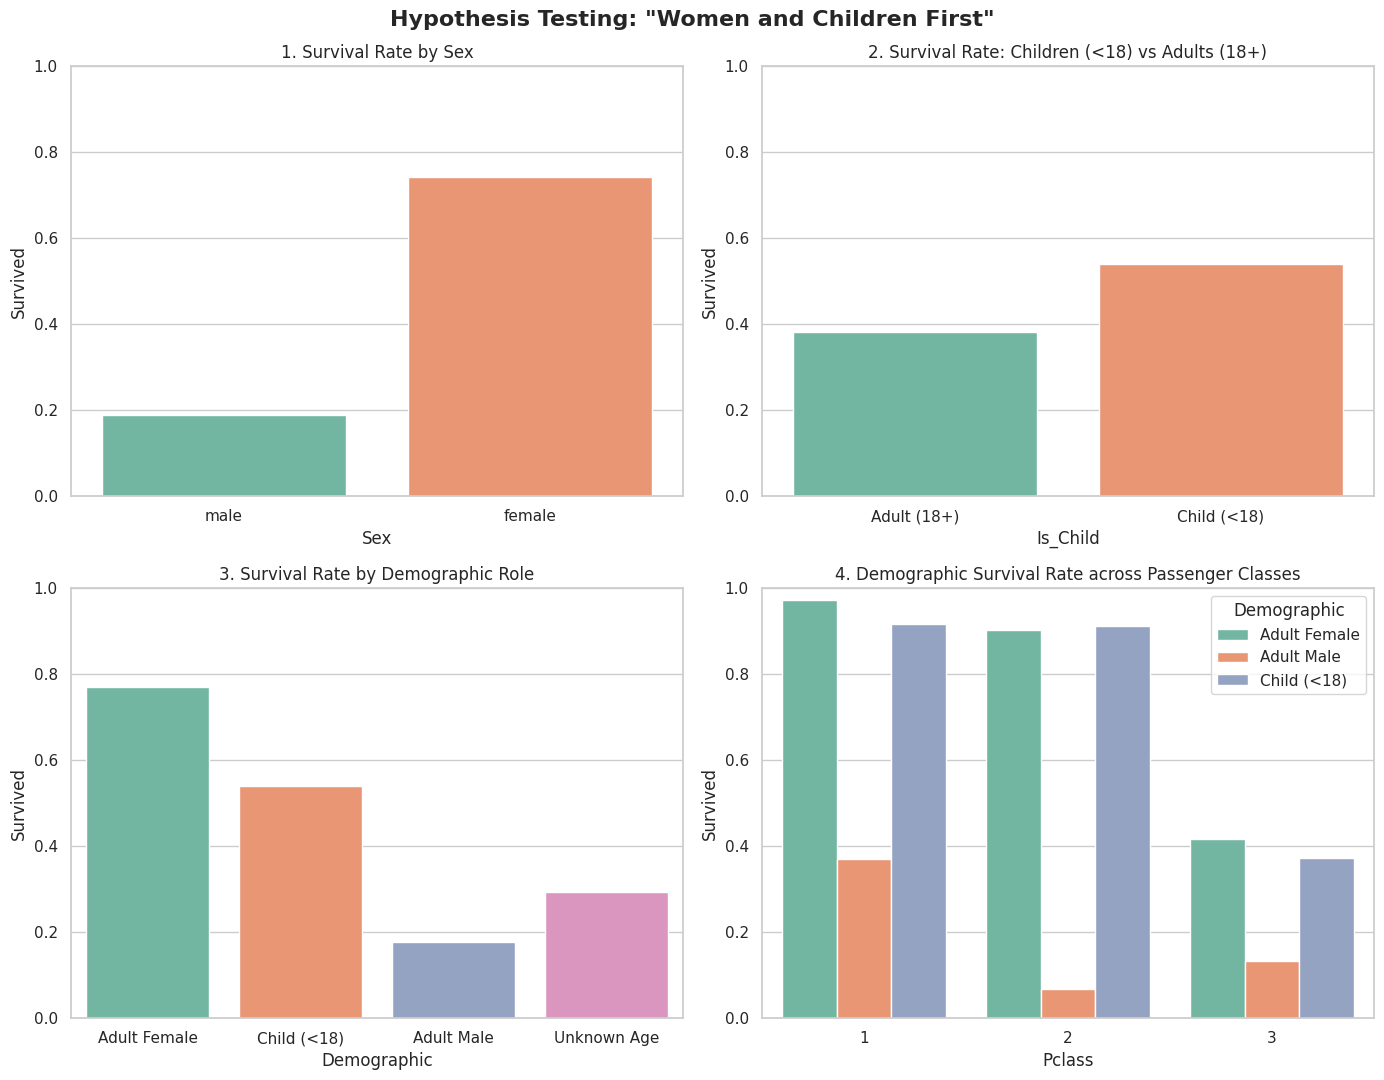

In [16]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle('Hypothesis Testing: "Women and Children First"', fontsize=16, fontweight='bold', y=0.98)

sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0, 0], palette='Set2', errorbar=None)
axes[0, 0].set_title('1. Survival Rate by Sex')
axes[0, 0].set_ylim(0, 1)

sns.barplot(x='Is_Child', y='Survived', data=known_age, ax=axes[0, 1], palette='Set2', errorbar=None)
axes[0, 1].set_title('2. Survival Rate: Children (<18) vs Adults (18+)')
axes[0, 1].set_ylim(0, 1)

demo_order = ['Adult Female', 'Child (<18)', 'Adult Male', 'Unknown Age']
sns.barplot(x='Demographic', y='Survived', data=df, order=demo_order, ax=axes[1, 0], palette='Set2', errorbar=None)
axes[1, 0].set_title('3. Survival Rate by Demographic Role')
axes[1, 0].set_ylim(0, 1)

demo_known = df[df['Demographic'] != 'Unknown Age']
sns.barplot(x='Pclass', y='Survived', hue='Demographic', data=demo_known, ax=axes[1, 1], palette='Set2', errorbar=None)
axes[1, 1].set_title('4. Demographic Survival Rate across Passenger Classes')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [17]:
df = pd.read_csv('titanic.csv')

In [21]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
outlier_summary = []

for col in num_cols:
    data = df[col].dropna()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = data[(data < lower_bound) | (data > upper_bound)]
    z_outliers = data[np.abs((data - data.mean()) / data.std()) > 3]

    outlier_summary.append({
        'Variable': col,
        'Count': len(data),
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Upper Bound': round(upper_bound, 2),
        'IQR Outliers': len(outliers),
        'Outlier %': round(len(outliers) / len(data) * 100, 2),
        '|Z| > 3 Count': len(z_outliers),
        'Max Value': round(data.max(), 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
print("=== OUTLIER STATISTICAL SUMMARY ===")
print(outlier_df.to_string(index=False))

=== OUTLIER STATISTICAL SUMMARY ===
Variable  Count    Q1   Q3   IQR  Upper Bound  IQR Outliers  Outlier %  |Z| > 3 Count  Max Value
     Age    714 20.12 38.0 17.88        64.81            11       1.54              2      80.00
    Fare    891  7.91 31.0 23.09        65.63           116      13.02             20     512.33
   SibSp    891  0.00  1.0  1.00         2.50            46       5.16             30       8.00
   Parch    891  0.00  0.0  0.00         0.00           213      23.91             15       6.00


/tmp/ipykernel_4266/1188437660.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='FamilySize', data=df, ax=axes[1, 1], palette='crest')


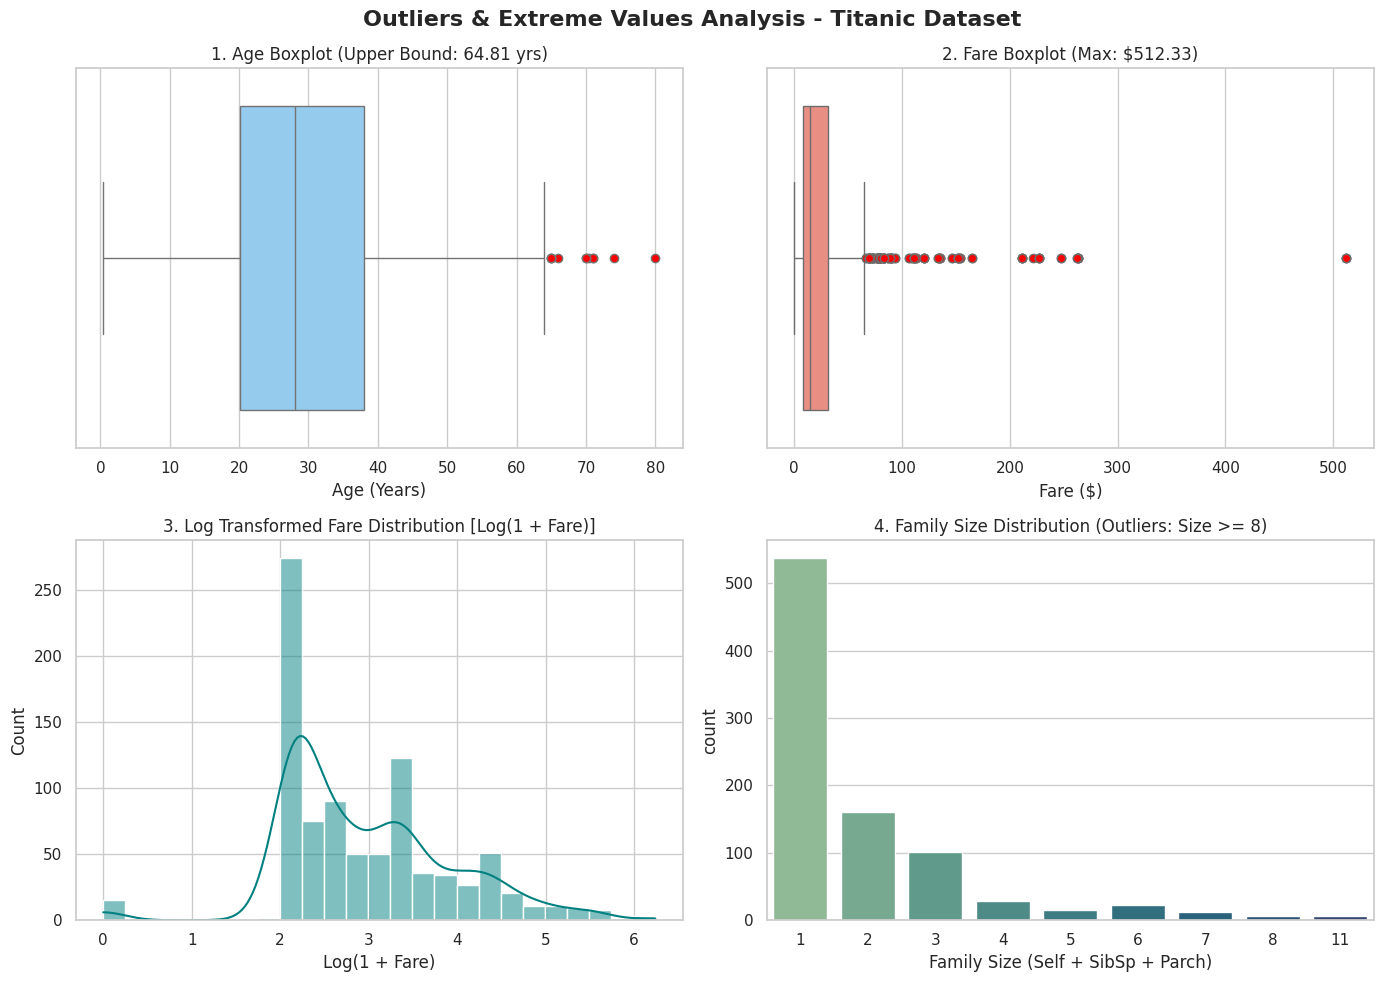

In [22]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Outliers & Extreme Values Analysis - Titanic Dataset', fontsize=16, fontweight='bold', y=0.98)

# Chart 1: Age Boxplot
sns.boxplot(x=df['Age'], ax=axes[0, 0], color='lightskyblue', flierprops=dict(marker='o', markerfacecolor='red', markersize=6))
axes[0, 0].set_title('1. Age Boxplot (Upper Bound: 64.81 yrs)')
axes[0, 0].set_xlabel('Age (Years)')

# Chart 2: Fare Boxplot
sns.boxplot(x=df['Fare'], ax=axes[0, 1], color='salmon', flierprops=dict(marker='o', markerfacecolor='red', markersize=6))
axes[0, 1].set_title('2. Fare Boxplot (Max: $512.33)')
axes[0, 1].set_xlabel('Fare ($)')

# Chart 3: Log Transformed Fare
df['Log_Fare'] = np.log1p(df['Fare'])
sns.histplot(df['Log_Fare'], kde=True, ax=axes[1, 0], color='teal', bins=25)
axes[1, 0].set_title('3. Log Transformed Fare Distribution [Log(1 + Fare)]')
axes[1, 0].set_xlabel('Log(1 + Fare)')

# Chart 4: Family Size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
sns.countplot(x='FamilySize', data=df, ax=axes[1, 1], palette='crest')
axes[1, 1].set_title('4. Family Size Distribution (Outliers: Size >= 8)')
axes[1, 1].set_xlabel('Family Size (Self + SibSp + Parch)')

plt.tight_layout()
plt.show()

In [23]:
print("=== MISSING VALUES BEFORE IMPUTATION ===")
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
})
print(missing_summary[missing_summary['Missing Count'] > 0])

=== MISSING VALUES BEFORE IMPUTATION ===
          Missing Count  Missing %
Age                 177      19.87
Cabin               687      77.10
Embarked              2       0.22


In [24]:
mode_embarked = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(mode_embarked)

In [25]:
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_4266/172848211.py:1: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [27]:
title_mapping = {
    "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
    "Dr": "Rare", "Rev": "Rare", "Col": "Rare", "Major": "Rare",
    "Mlle": "Miss", "Countess": "Rare", "Ms": "Miss", "Lady": "Rare",
    "Jonkheer": "Rare", "Don": "Rare", "Dona": "Rare", "Mme": "Mrs",
    "Capt": "Rare", "Sir": "Rare"
}
df['Title_Group'] = df['Title'].map(title_mapping)

In [28]:
df['Age'] = df.groupby(['Title_Group', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))

In [29]:
df['Deck'] = df['Cabin'].apply(lambda x: str(x)[0] if pd.notna(x) else 'U')
df['Has_Cabin'] = df['Cabin'].apply(lambda x: 0 if pd.isna(x) else 1)

In [30]:
print("\n=== MISSING VALUES AFTER IMPUTATION ===")
print(df[['Age', 'Embarked', 'Deck', 'Has_Cabin']].isnull().sum())


=== MISSING VALUES AFTER IMPUTATION ===
Age          0
Embarked     0
Deck         0
Has_Cabin    0
dtype: int64


/tmp/ipykernel_4266/153043569.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Deck', data=df, order=deck_order, ax=axes[1], palette='Blues_r')


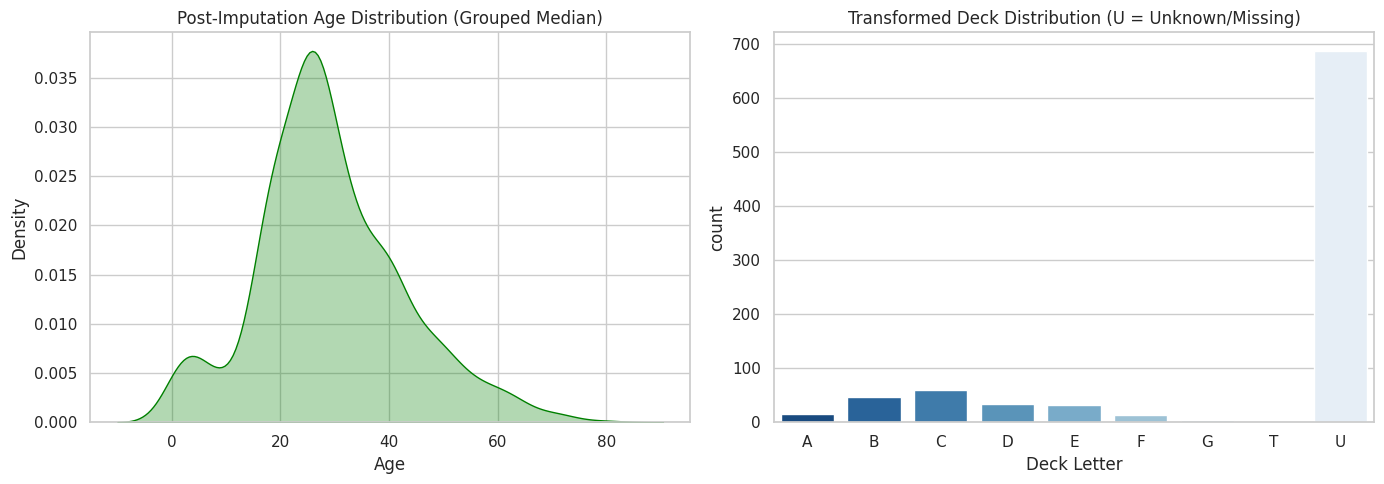

In [31]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Age Distribution before/after
sns.kdeplot(df['Age'], ax=axes[0], color='green', fill=True, alpha=0.3)
axes[0].set_title('Post-Imputation Age Distribution (Grouped Median)')
axes[0].set_xlabel('Age')

# Plot 2: Deck Categories
deck_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T', 'U']
sns.countplot(x='Deck', data=df, order=deck_order, ax=axes[1], palette='Blues_r')
axes[1].set_title('Transformed Deck Distribution (U = Unknown/Missing)')
axes[1].set_xlabel('Deck Letter')

plt.tight_layout()
plt.show()

In [32]:
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
title_mapping = {
    "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
    "Dr": "Rare", "Rev": "Rare", "Col": "Rare", "Major": "Rare",
    "Mlle": "Miss", "Countess": "Rare", "Ms": "Miss", "Lady": "Rare",
    "Jonkheer": "Rare", "Don": "Rare", "Dona": "Rare", "Mme": "Mrs",
    "Capt": "Rare", "Sir": "Rare"
}
df['Title_Group'] = df['Title'].map(title_mapping)

<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_4266/2246337263.py:1: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [33]:
df['Age'] = df.groupby(['Title_Group', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))

In [34]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

def classify_family(size):
    if size == 1:
        return 'Alone'
    elif 2 <= size <= 4:
        return 'Small Family'
    else:
        return 'Large Family'

df['FamilyCategory'] = df['FamilySize'].apply(classify_family)

In [35]:
ticket_counts = df['Ticket'].value_counts()
df['GroupSize'] = df['Ticket'].map(ticket_counts)
df['Fare_Per_Person'] = df['Fare'] / df['GroupSize']
df['Log_Fare'] = np.log1p(df['Fare'])

In [36]:
df['Deck'] = df['Cabin'].apply(lambda x: str(x)[0] if pd.notna(x) else 'U')
df['Has_Cabin'] = df['Cabin'].apply(lambda x: 0 if pd.isna(x) else 1)

In [37]:
df['Age_Pclass'] = df['Age'] * df['Pclass']

/tmp/ipykernel_4266/3125168060.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Title_Group', y='Survived', data=df, ax=axes[0, 0], palette='Blues_d', errorbar=None)
/tmp/ipykernel_4266/3125168060.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='FamilyCategory', y='Survived', data=df, order=['Alone', 'Small Family', 'Large Family'], ax=axes[0, 1], palette='Greens_d', errorbar=None)
/tmp/ipykernel_4266/3125168060.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Deck', y='Survived', data=df[df['Deck']!='T'], order=deck_orde

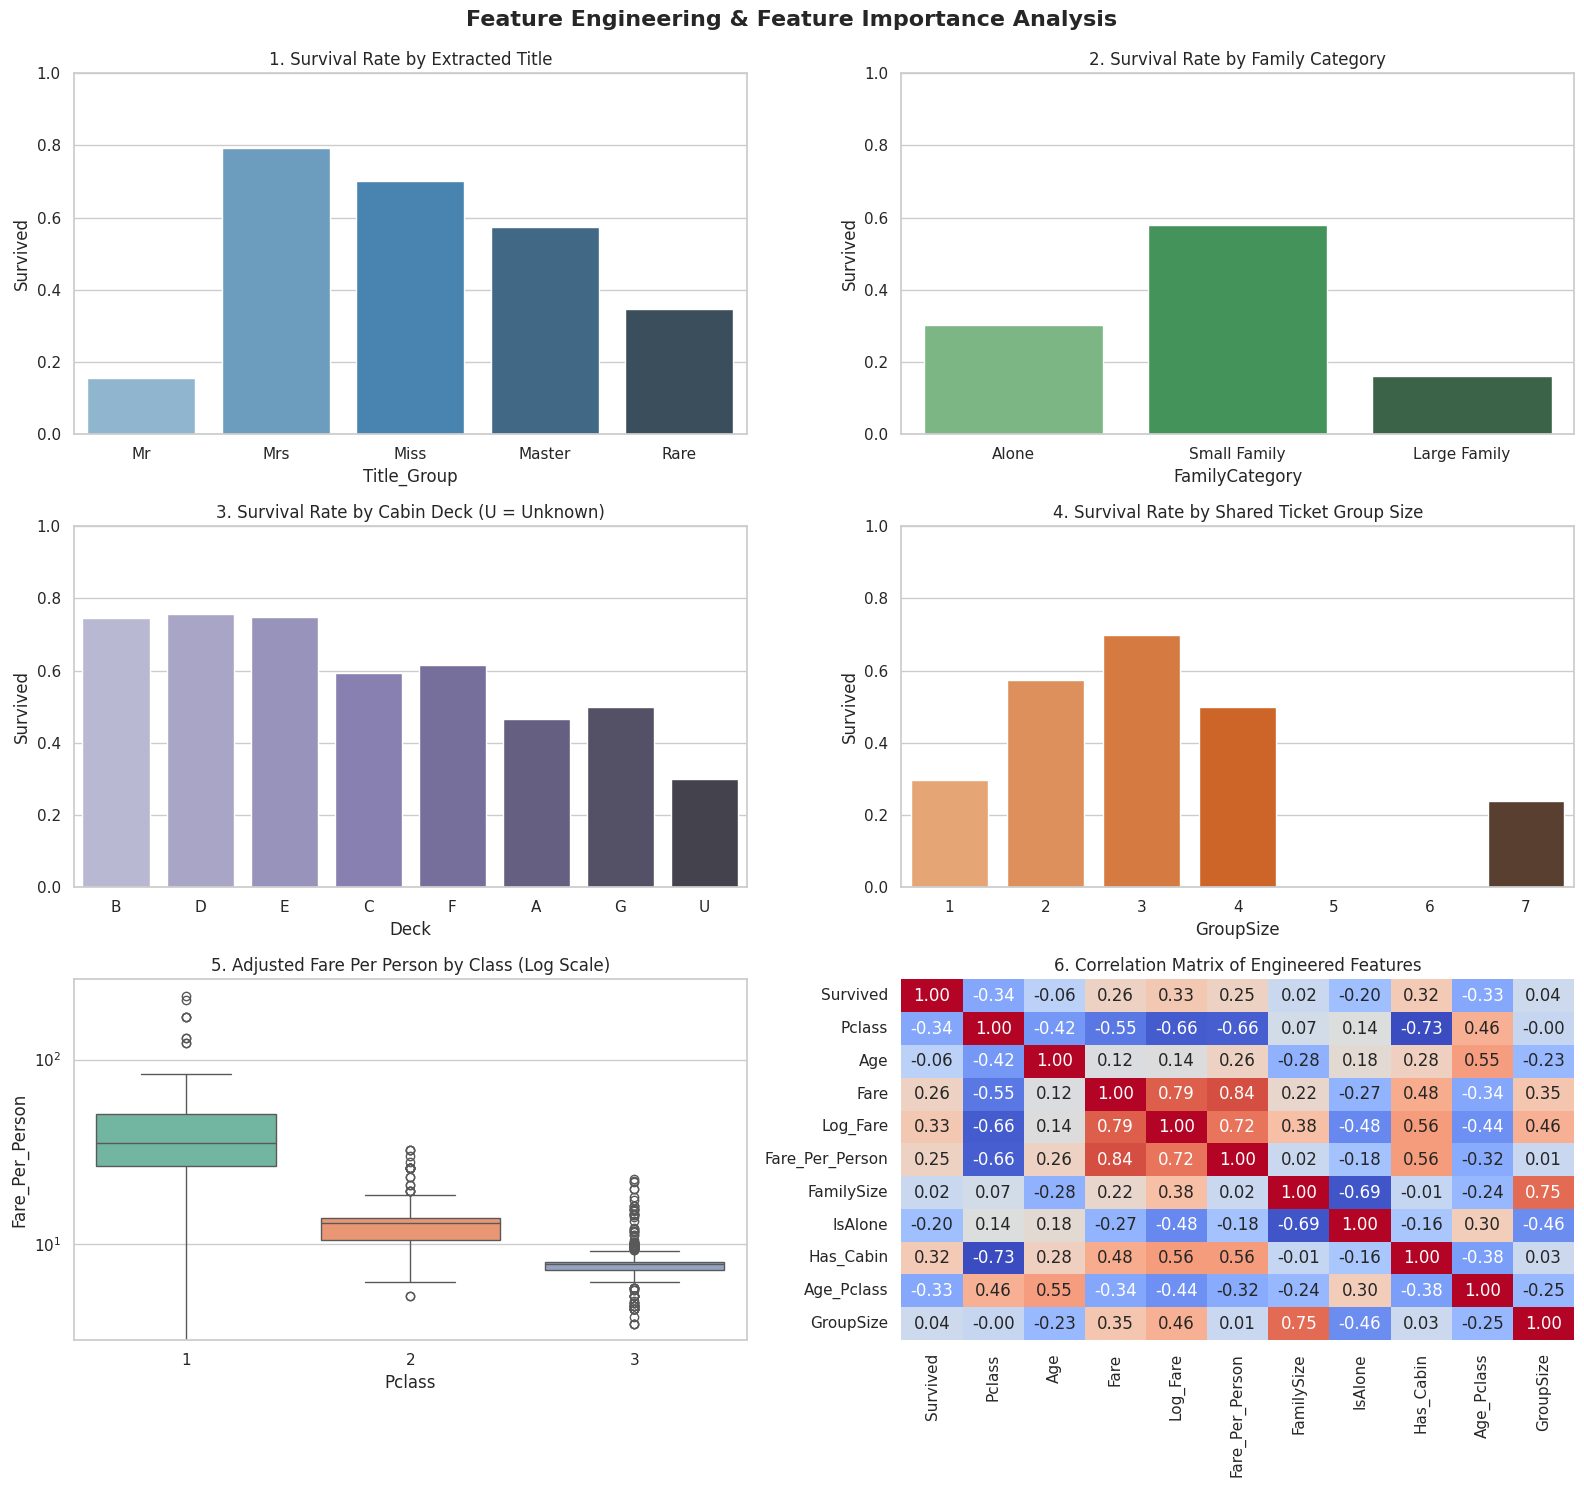

In [39]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
fig.suptitle('Feature Engineering & Feature Importance Analysis', fontsize=16, fontweight='bold', y=0.99)

# Plot 1: Title Group Survival
sns.barplot(x='Title_Group', y='Survived', data=df, ax=axes[0, 0], palette='Blues_d', errorbar=None)
axes[0, 0].set_title('1. Survival Rate by Extracted Title')
axes[0, 0].set_ylim(0, 1)

# Plot 2: Family Category Survival
sns.barplot(x='FamilyCategory', y='Survived', data=df, order=['Alone', 'Small Family', 'Large Family'], ax=axes[0, 1], palette='Greens_d', errorbar=None)
axes[0, 1].set_title('2. Survival Rate by Family Category')
axes[0, 1].set_ylim(0, 1)

# Plot 3: Deck Survival
deck_order = ['B', 'D', 'E', 'C', 'F', 'A', 'G', 'U']
sns.barplot(x='Deck', y='Survived', data=df[df['Deck']!='T'], order=deck_order, ax=axes[1, 0], palette='Purples_d', errorbar=None)
axes[1, 0].set_title('3. Survival Rate by Cabin Deck (U = Unknown)')
axes[1, 0].set_ylim(0, 1)

# Plot 4: Group Size Survival
sns.barplot(x='GroupSize', y='Survived', data=df, ax=axes[1, 1], palette='Oranges_d', errorbar=None)
axes[1, 1].set_title('4. Survival Rate by Shared Ticket Group Size')
axes[1, 1].set_ylim(0, 1)

# Plot 5: Fare Per Person Boxplot
sns.boxplot(x='Pclass', y='Fare_Per_Person', data=df, ax=axes[2, 0], palette='Set2')
axes[2, 0].set_yscale('log')
axes[2, 0].set_title('5. Adjusted Fare Per Person by Class (Log Scale)')

# Plot 6: Correlation Matrix Heatmap
corr_features = df[['Survived', 'Pclass', 'Age', 'Fare', 'Log_Fare', 'Fare_Per_Person',
                    'FamilySize', 'IsAlone', 'Has_Cabin', 'Age_Pclass', 'GroupSize']].corr()
sns.heatmap(corr_features, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[2, 1], cbar=False)
axes[2, 1].set_title('6. Correlation Matrix of Engineered Features')

plt.tight_layout()
plt.show()

We can now import the data into pandas as before:

In [ ]:
students = pd.read_csv('students.csv')
students.head()

,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,group B,bachelor's degree,standard,none,72,72,74
1,group C,some college,standard,completed,69,90,88
2,group B,master's degree,standard,none,90,95,93
3,group A,associate's degree,free/reduced,none,47,57,44
4,group C,some college,standard,none,76,78,75


We can find the number of rows and columns with ".shape":

In [ ]:
students.shape

(1000, 7)

1000 rows and 7 columns. We can get informtaion about the data using the _info_ function:

In [ ]:
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   race/ethnicity               1000 non-null   object
 1   parental level of education  1000 non-null   object
 2   lunch                        1000 non-null   object
 3   test preparation course      1000 non-null   object
 4   math score                   1000 non-null   int64 
 5   reading score                1000 non-null   int64 
 6   writing score                1000 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 54.8+ KB


We can see from this our data items are of the type 'object' (meaning string) or int64 (64-bit integers). We can also see that each has "1000 non-null" records and there are "1000 entries". Seemingly there is no missing data but we can of course verify that with code we used in our previous pandas' Notebooks:

In [ ]:
students.isnull().sum()

,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


No missing data! If we had found some there are various options including deleting the rows (see the previous Notebook) effected or even deleting the columns. If we want to check if its sensible to delete a column we may want to see the percentage of the column's data that is missing:

In [ ]:
# Percent of data which is not available
students.isnull().sum()/len(students) * 100

,0
race/ethnicity,0.0
parental level of education,0.0
lunch,0.0
test preparation course,0.0
math score,0.0
reading score,0.0
writing score,0.0


We can find the number of unique and duplicated rows:

In [ ]:
students.duplicated().value_counts()

,count
False,1000


No duplicates (i.e. there are 1000 records for which its False that the record is a duplicate). Pandas will also give us summary statistics about this data:

In [ ]:
students.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


We can see that only three of the columns have been "described" ... the three that were numeric (int64). For each, we get a range of useful measures including the mean average, the standard deviation, minimum and maximum values, and the 25th, 50th (median) and 75th percentyles.

### Visualising the Data

[]

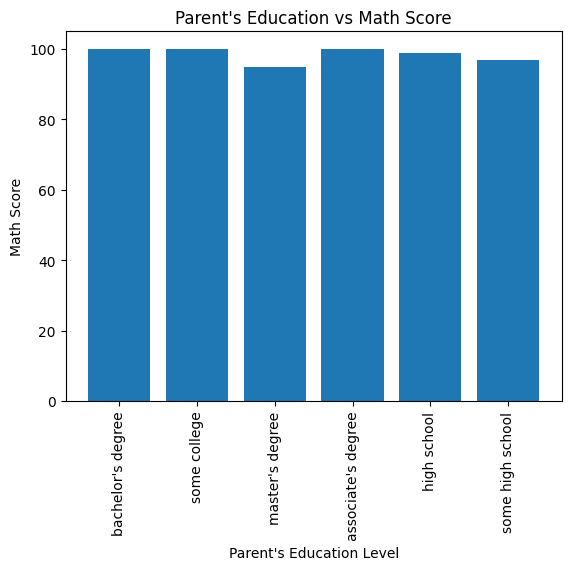

In [ ]:
plt.bar(students['parental level of education'], students['math score']) # create a bar chart of the two values
# note we use a "\" symbol so that the apostrophy doesn't close the string
plt.xlabel('Parent\'s Education Level') # x-axis is parent's education level
plt.xticks(rotation=90) # rotate x labels 90 degrees (vertical)
plt.ylabel('Math Score') # y-axis is maths score
plt.title('Parent\'s Education vs Math Score') # add title
plt.plot() # plot the chart to screen

Interstingly if you parents had masters-level education your math score is lower! Let's try another:

[]

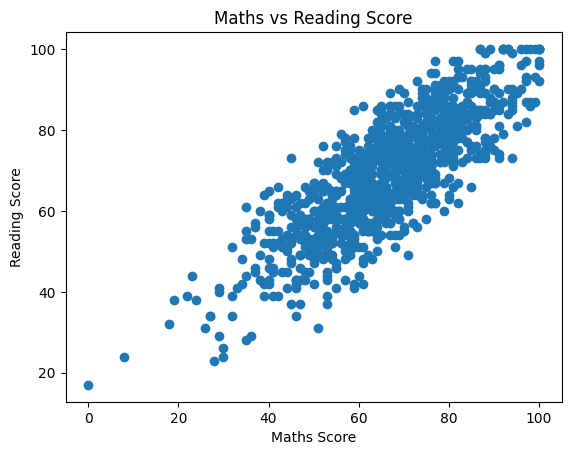

In [ ]:
plt.scatter(students['math score'], students['reading score'])
plt.xlabel('Maths Score')
plt.ylabel('Reading Score')
plt.title('Maths vs Reading Score')
plt.plot()

Again, perhaps unsurprisingly, there seems to be good correlation between maths performance and reading performance (they trend together).

We may also want to see how "normal" our data is - i.e. does it follow a [normal distribution](https://en.wikipedia.org/wiki/Normal_distribution). Let's check with a histogram:

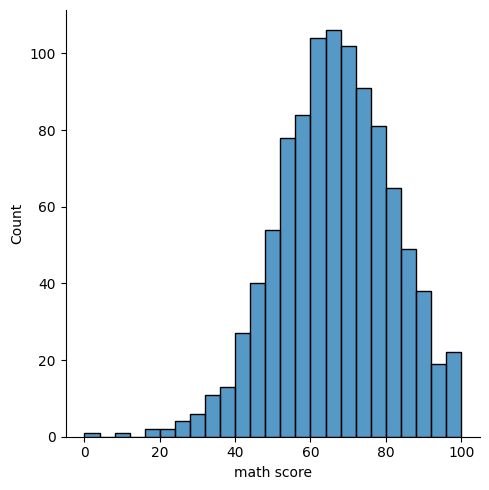

In [ ]:
ax = sns.displot(students['math score'])

Whilst this is not exactly normal - slightly skewed - its probably fine in practice.

We can use the _pairplot( )_ method to visualise pairs of variables:

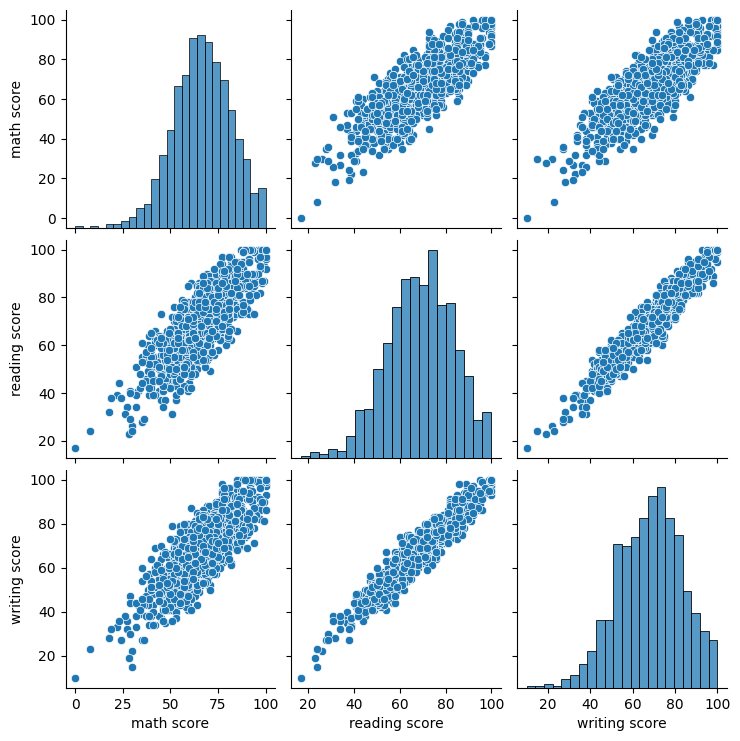

In [ ]:
sns.pairplot(data = students[['math score','reading score','writing score']],diag_kind='hist')

Here we have the scatter plot when comparing two variables, and when its only a single variable we have a histogram.

We may also decide to remove a variable:

In [ ]:
students = students.drop(['lunch'], axis=1)
students.head()

,race/ethnicity,parental level of education,test preparation course,math score,reading score,writing score
0,group B,bachelor's degree,none,72,72,74
1,group C,some college,completed,69,90,88
2,group B,master's degree,none,90,95,93
3,group A,associate's degree,none,47,57,44
4,group C,some college,none,76,78,75


Obviously don't drop lunch in the real-world ... you will get hungry.

And that's it! There are of course many of things we could do but this is a fairly typical example of an EDA process. Well done :)

